<a href="https://colab.research.google.com/github/PritiPojage/DMA_Cervical_Cancer_Mini_Project/blob/main/DMA_Cervical_cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    KBinsDiscretizer
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif

# Classification
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

# Cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

# Clustering
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Imbalanced data
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Association rule mining
from mlxtend.frequent_patterns import apriori, association_rules

print("Libraries imported successfully!")

Libraries imported successfully!


# Load the Cervical Cancer dataset

In [ ]:
url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/00383/"
    "risk_factors_cervical_cancer.csv"
)

df = pd.read_csv(url, na_values="?")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully
Dataset shape: (858, 36)


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
2,34,1.0,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.0,0.0,...,NaN,NaN,1,0,1,0,0,0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0


# Understand the dataset

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 858 entries, 0 to 857
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 858 non-null    int64  
 1   Number of sexual partners           832 non-null    float64
 2   First sexual intercourse            851 non-null    float64
 3   Num of pregnancies                  802 non-null    float64
 4   Smokes                              845 non-null    float64
 5   Smokes (years)                      845 non-null    float64
 6   Smokes (packs/year)                 845 non-null    float64
 7   Hormonal Contraceptives             750 non-null    float64
 8   Hormonal Contraceptives (years)     750 non-null    float64
 9   IUD                                 741 non-null    float64
 10  IUD (years)                         741 non-null    float64
 11  STDs                    

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
count,858.000000,832.000000,851.000000,802.000000,845.000000,845.000000,845.000000,750.000000,750.000000,741.000000,...,71.000000,71.000000,858.000000,858.000000,858.000000,858.000000,858.000000,858.000000,858.000000,858.000000
mean,26.820513,2.527644,16.995300,2.275561,0.145562,1.219721,0.453144,0.641333,2.256419,0.112011,...,6.140845,5.816901,0.020979,0.010490,0.020979,0.027972,0.040793,0.086247,0.051282,0.064103
std,8.497948,1.667760,2.803355,1.447414,0.352876,4.089017,2.226610,0.479929,3.764254,0.315593,...,5.895024,5.755271,0.143398,0.101939,0.143398,0.164989,0.197925,0.280892,0.220701,0.245078
min,13.000000,1.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,20.000000,2.000000,15.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,25.000000,2.000000,17.000000,2.000000,0.000000,0.000000,0.000000,1.000000,0.500000,0.000000,...,4.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,32.000000,3.000000,18.000000,3.000000,0.000000,0.000000,0.000000,1.000000,3.000000,0.000000,...,8.000000,7.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,84.000000,28.000000,32.000000,11.000000,1.000000,37.000000,37.000000,1.000000,30.000000,1.000000,...,22.000000,22.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Missing values:
Age                                     0
Number of sexual partners              26
First sexual intercourse                7
Num of pregnancies                     56
Smokes                                 13
Smokes (years)                         13
Smokes (packs/year)                    13
Hormonal Contraceptives               108
Hormonal Contraceptives (years)       108
IUD                                   117
IUD (years)                           117
STDs                                  105
STDs (number)                         105
STDs:condylomatosis                   105
STDs:cervical condylomatosis          105
STDs:vaginal condylomatosis           105
STDs:vulvo-perineal condylomatosis    105
STDs:syphilis                         105
STDs:pelvic inflammatory disease      105
STDs:genital herpes                   105
STDs:molluscum contagiosum            105
STDs:AIDS                             105
STDs:HIV                              105
STDs:Hepatitis B 

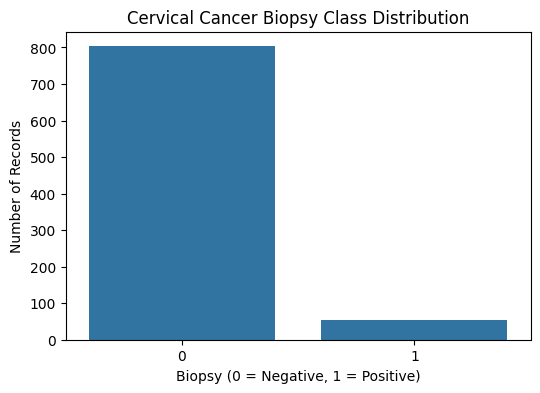

In [ ]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nBiopsy distribution:")
print(df["Biopsy"].value_counts())

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Biopsy")

plt.title("Cervical Cancer Biopsy Class Distribution")
plt.xlabel("Biopsy (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Records")

plt.show()

# Requirement 1 – Data Preprocessing
Preprocessing prepares raw data before applying machine learning algorithms.

We will perform:
1. Missing-value identification.
2. Removal of highly incomplete attributes.
3. Duplicate checking.
4. Numerical data conversion.
5. Missing-value imputation.
6. Normalization using StandardScaler.

**1.Identify attributes and missing values**

In [ ]:
df = df.apply(pd.to_numeric, errors="coerce")

print("Original number of attributes:", len(df.columns))

print("\nMissing value percentage:")

missing_percentage = df.isnull().mean() * 100

display(
    missing_percentage[missing_percentage > 0]
    .sort_values(ascending=False)
)

Original number of attributes: 36

Missing value percentage:


,0
STDs: Time since first diagnosis,91.724942
STDs: Time since last diagnosis,91.724942
IUD (years),13.636364
IUD,13.636364
Hormonal Contraceptives,12.587413
Hormonal Contraceptives (years),12.587413
STDs (number),12.237762
STDs,12.237762
STDs:vulvo-perineal condylomatosis,12.237762
STDs:vaginal condylomatosis,12.237762


#Separate features and target

In [ ]:
# Target attribute
target = "Biopsy"

# Input attributes
X = df.drop(columns=[target]).copy()

# Output attribute
y = df[target].copy()

# Remove records where target is missing
valid = y.notna()

X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].astype(int).reset_index(drop=True)

print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features: (858, 35)
Target: (858,)

Target distribution:
Biopsy
0    803
1     55
Name: count, dtype: int64


# NumericToNominal conversion

In [ ]:
# WEKA's 1-based attribute positions
weka_nominal_positions = [
    5, 8, 10, 12,
    14, 15, 16, 17, 18, 19,
    20, 21, 22, 23, 24, 25
]

nominal_columns = [
    X.columns[i - 1]
    for i in weka_nominal_positions
    if i <= len(X.columns)
]

print("Attributes selected for nominal conversion:")
print(nominal_columns)

for col in nominal_columns:
    X[col] = X[col].apply(
        lambda value: str(int(value)) if pd.notna(value) else np.nan
    )

# Final class attribute is nominal
y = y.astype(str)

print("\nNumericToNominal conversion completed.")

Attributes selected for nominal conversion:
['Smokes', 'Hormonal Contraceptives', 'IUD', 'STDs', 'STDs:condylomatosis', 'STDs:cervical condylomatosis', 'STDs:vaginal condylomatosis', 'STDs:vulvo-perineal condylomatosis', 'STDs:syphilis', 'STDs:pelvic inflammatory disease', 'STDs:genital herpes', 'STDs:molluscum contagiosum', 'STDs:AIDS', 'STDs:HIV', 'STDs:Hepatitis B', 'STDs:HPV']

NumericToNominal conversion completed.


# ReplaceMissingValues and RemoveUseless

In [ ]:
# Separate numeric and nominal features
numeric_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

nominal_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Replace missing numeric values with mean
numeric_imputer = SimpleImputer(strategy="mean")

if numeric_columns:
    X[numeric_columns] = numeric_imputer.fit_transform(
        X[numeric_columns]
    )

# Replace missing nominal values with mode
for col in nominal_columns:

    mode_value = X[col].mode()

    if not mode_value.empty:
        X[col] = X[col].fillna(mode_value.iloc[0])

# Approximate WEKA RemoveUseless (M99.0)
useless_columns = []

for col in X.columns:

    dominant_percentage = (
        X[col].value_counts(normalize=True).max() * 100
    )

    if dominant_percentage > 99:
        useless_columns.append(col)

X.drop(columns=useless_columns, inplace=True)

print("Removed useless attributes:", useless_columns)
print("Final number of features:", X.shape[1])

print("\nRemaining missing values:", X.isnull().sum().sum())

Removed useless attributes: ['STDs:cervical condylomatosis', 'STDs:vaginal condylomatosis', 'STDs:pelvic inflammatory disease', 'STDs:genital herpes', 'STDs:molluscum contagiosum', 'STDs:AIDS', 'STDs:Hepatitis B', 'STDs:HPV']
Final number of features: 27

Remaining missing values: 0


# Standardization for distance-based analysis

In [ ]:
scaler = StandardScaler()

X_numeric = X.apply(
    pd.to_numeric,
    errors="coerce"
)

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_numeric),
    columns=X_numeric.columns
)

print("Standardization completed for Python analysis.")

Standardization completed for Python analysis.


# Requirement 2 – Supervised Learning
Supervised learning uses labelled data to predict an output.

Our target variable is Biopsy:
- 0 = Negative
- 1 = Positive
We will implement three algorithms:
1. Decision Tree (J48-style)
2. RandomForest
3. NaiveBayes

#1.Define models and cross-validation

In [ ]:
models = {
    "Decision Tree (J48-style)": DecisionTreeClassifier(
        random_state=10
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=100,
        random_state=10
    ),

    "NaiveBayes": GaussianNB()
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=10
)

print("Stratified 10-fold cross-validation configured.")

Stratified 10-fold cross-validation configured.


# Preprocessing pipeline and model evaluation

In [ ]:
from sklearn.compose import ColumnTransformer

numeric_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

def make_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

results = {}

for name, model in models.items():

    pipeline = ImbPipeline([
        ("preprocessing", make_preprocessor()),
        ("classifier", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X,
        y.astype(int),
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    results[name] = {
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    }

results_df = pd.DataFrame(results).T

print("Baseline Classification Results:")
display(results_df.round(4))

Baseline Classification Results:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Decision Tree (J48-style),0.9394,0.5100,0.4200,0.4535,0.6976
RandomForest,0.9499,0.6600,0.4733,0.5367,0.9581
NaiveBayes,0.8089,0.2453,0.9500,0.3892,0.8919


# Calculate Cohen's Kappa

In [ ]:
from sklearn.model_selection import cross_val_predict

for name, model in models.items():

    pipeline = ImbPipeline([
        ("preprocessing", make_preprocessor()),
        ("classifier", clone(model))
    ])

    predictions = cross_val_predict(
        pipeline,
        X,
        y.astype(int),
        cv=cv,
        method="predict"
    )

    kappa = cohen_kappa_score(
        y.astype(int),
        predictions
    )

    results_df.loc[name, "Kappa"] = kappa

    print(name, "Kappa:", round(kappa, 4))

display(results_df.round(4))

Decision Tree (J48-style) Kappa: 0.4378
RandomForest Kappa: 0.5215
NaiveBayes Kappa: 0.3186


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Kappa
Decision Tree (J48-style),0.9394,0.5100,0.4200,0.4535,0.6976,0.4378
RandomForest,0.9499,0.6600,0.4733,0.5367,0.9581,0.5215
NaiveBayes,0.8089,0.2453,0.9500,0.3892,0.8919,0.3186


# Classification performance graph

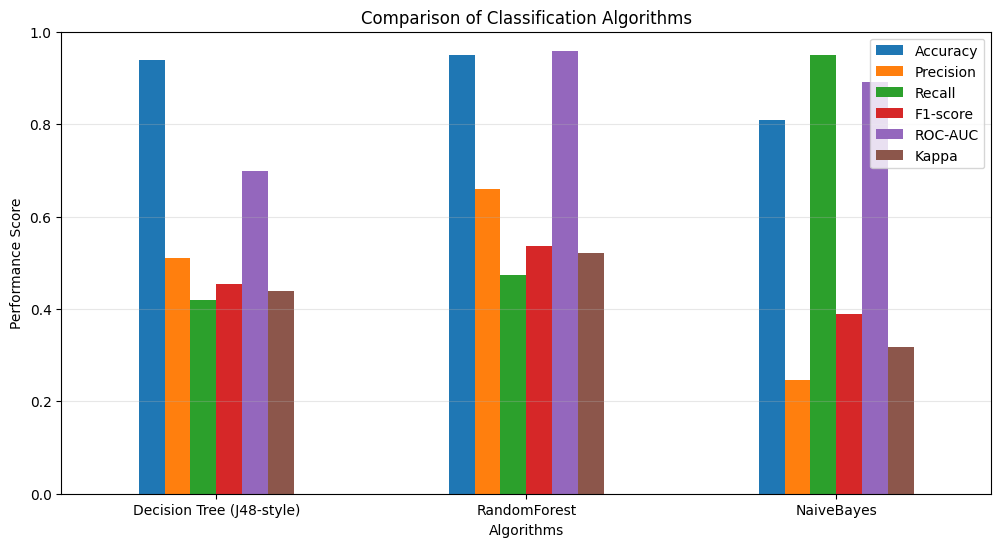

In [ ]:
results_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Classification Algorithms")
plt.ylabel("Performance Score")
plt.xlabel("Algorithms")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

# Requirement 3 – Unsupervised Learning (K-Means)
Unsupervised learning discovers groups in data without using predefined output labels.

We will use K-Means clustering to divide the patient records into two clusters.

Important: Biopsy must not be used while creating the clusters.

# Prepare data for clustering

In [ ]:
# Use input features only. Biopsy is excluded.
cluster_data = df.drop(columns=["Biopsy"]).copy()

# Convert selected categorical attributes to strings
for col in nominal_columns:
    if col in cluster_data.columns:
        cluster_data[col] = cluster_data[col].apply(
            lambda v: str(int(v)) if pd.notna(v) else np.nan
        )

# Impute missing values
cluster_numeric = cluster_data.select_dtypes(
    include=["number"]
).columns.tolist()

cluster_categorical = cluster_data.select_dtypes(
    include=["object"]
).columns.tolist()

for col in cluster_numeric:
    cluster_data[col] = cluster_data[col].fillna(
        cluster_data[col].median()
    )

for col in cluster_categorical:
    cluster_data[col] = cluster_data[col].fillna(
        cluster_data[col].mode()[0]
    )

# One-hot encode categorical attributes
cluster_encoded = pd.get_dummies(
    cluster_data,
    columns=cluster_categorical,
    dtype=int
)

# Standardize
cluster_scaler = StandardScaler()

cluster_scaled = cluster_scaler.fit_transform(
    cluster_encoded
)

print("Clustering data shape:", cluster_scaled.shape)

Clustering data shape: (858, 49)


# Apply K-Means

In [ ]:
kmeans = KMeans(
    n_clusters=2,
    max_iter=500,
    random_state=10,
    n_init=10
)

clusters = kmeans.fit_predict(cluster_scaled)

print("K-Means completed!")

print("Iterations:", kmeans.n_iter_)
print("Within-cluster SSE:", kmeans.inertia_)

print("\nCluster distribution:")
print(pd.Series(clusters).value_counts().sort_index())

K-Means completed!
Iterations: 8
Within-cluster SSE: 34166.78101491933

Cluster distribution:
0     78
1    780
Name: count, dtype: int64


# Visualize clusters using PCA

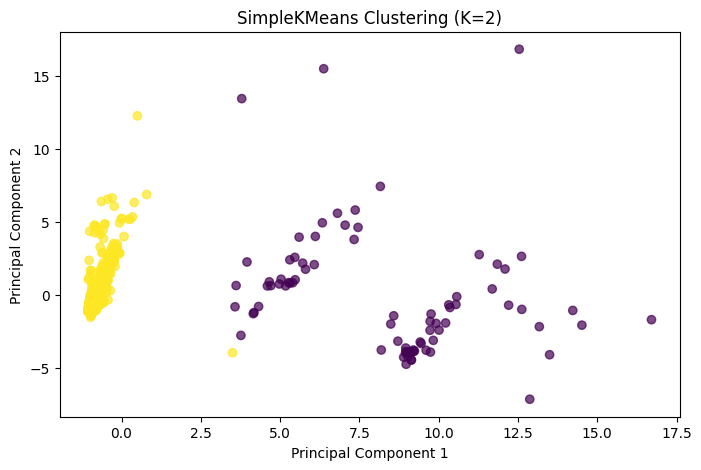

In [ ]:
pca = PCA(n_components=2)

pca_result = pca.fit_transform(cluster_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    c=clusters,
    cmap="viridis",
    alpha=0.7
)

plt.title("SimpleKMeans Clustering (K=2)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

# Compare clusters with Biopsy after clustering

In [ ]:
cluster_comparison = pd.crosstab(
    y.astype(int),
    clusters,
    rownames=["Actual Biopsy"],
    colnames=["Cluster"]
)

print("Actual Biopsy vs K-Means Cluster:")
display(cluster_comparison)

#Calculate the number of incorrectly matched records using the best one-to-one cluster-to-class mapping:
from scipy.optimize import linear_sum_assignment

matrix = cluster_comparison.reindex(
    index=[0, 1],
    columns=[0, 1],
    fill_value=0
).values

row_ind, col_ind = linear_sum_assignment(-matrix)

correct = matrix[row_ind, col_ind].sum()
incorrect = len(y) - correct

print("Correctly matched records:", correct)
print("Incorrectly matched records:", incorrect)
print("Incorrect percentage:", round(
    incorrect / len(y) * 100, 3
), "%")

Actual Biopsy vs K-Means Cluster:


Cluster,0,1
Actual Biopsy,,
0,67,736
1,11,44


Correctly matched records: 747
Incorrectly matched records: 111
Incorrect percentage: 12.937 %


# Requirement 4 – Analyze Frequent Patterns using Apriori
Apriori is an association rule mining algorithm.

It identifies frequently occurring combinations of attributes.

For example:
- Customers buying bread may also buy butter.
- In our dataset, Apriori can discover co-occurrence patterns between recorded attributes.
We will use the Apriori algorithm from the mlxtend library.

#Prepare categorical data for Apriori

In [ ]:
# Exclude Biopsy from pattern mining
apriori_data = df.drop(columns=["Biopsy"]).copy()

# Identify numerical and categorical columns
num_cols = apriori_data.select_dtypes(
    include=["number"]
).columns.tolist()

cat_cols = apriori_data.select_dtypes(
    include=["object"]
).columns.tolist()

# Impute numerical values
for col in num_cols:
    apriori_data[col] = apriori_data[col].fillna(
        apriori_data[col].median()
    )

# Impute categorical values
for col in cat_cols:
    mode_value = apriori_data[col].mode()

    if not mode_value.empty:
        apriori_data[col] = apriori_data[col].fillna(
            mode_value[0]
        )

# Discretize numeric attributes into 10 bins
discretizer = KBinsDiscretizer(
    n_bins=10,
    encode="ordinal",
    strategy="uniform"
)

if num_cols:
    binned = discretizer.fit_transform(
        apriori_data[num_cols]
    )

    for i, col in enumerate(num_cols):
        apriori_data[col] = [
            f"Bin_{int(v)}" for v in binned[:, i]
        ]

# Convert all attributes into string categories
for col in apriori_data.columns:
    apriori_data[col] = (
        col + "=" + apriori_data[col].astype(str)
    )

print("Discretization completed!")

display(apriori_data.head())

Discretization completed!


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Number of diagnosis,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology
0,Age=Bin_0,Number of sexual partners=Bin_1,First sexual intercourse=Bin_2,Num of pregnancies=Bin_0,Smokes=Bin_0,Smokes (years)=Bin_0,Smokes (packs/year)=Bin_0,Hormonal Contraceptives=Bin_0,Hormonal Contraceptives (years)=Bin_0,IUD=Bin_0,...,STDs: Number of diagnosis=Bin_0,STDs: Time since first diagnosis=Bin_1,STDs: Time since last diagnosis=Bin_0,Dx:Cancer=Bin_0,Dx:CIN=Bin_0,Dx:HPV=Bin_0,Dx=Bin_0,Hinselmann=Bin_0,Schiller=Bin_0,Citology=Bin_0
1,Age=Bin_0,Number of sexual partners=Bin_0,First sexual intercourse=Bin_1,Num of pregnancies=Bin_0,Smokes=Bin_0,Smokes (years)=Bin_0,Smokes (packs/year)=Bin_0,Hormonal Contraceptives=Bin_0,Hormonal Contraceptives (years)=Bin_0,IUD=Bin_0,...,STDs: Number of diagnosis=Bin_0,STDs: Time since first diagnosis=Bin_1,STDs: Time since last diagnosis=Bin_0,Dx:Cancer=Bin_0,Dx:CIN=Bin_0,Dx:HPV=Bin_0,Dx=Bin_0,Hinselmann=Bin_0,Schiller=Bin_0,Citology=Bin_0
2,Age=Bin_2,Number of sexual partners=Bin_0,First sexual intercourse=Bin_3,Num of pregnancies=Bin_0,Smokes=Bin_0,Smokes (years)=Bin_0,Smokes (packs/year)=Bin_0,Hormonal Contraceptives=Bin_0,Hormonal Contraceptives (years)=Bin_0,IUD=Bin_0,...,STDs: Number of diagnosis=Bin_0,STDs: Time since first diagnosis=Bin_1,STDs: Time since last diagnosis=Bin_0,Dx:Cancer=Bin_0,Dx:CIN=Bin_0,Dx:HPV=Bin_0,Dx=Bin_0,Hinselmann=Bin_0,Schiller=Bin_0,Citology=Bin_0
3,Age=Bin_5,Number of sexual partners=Bin_1,First sexual intercourse=Bin_2,Num of pregnancies=Bin_3,Smokes=Bin_9,Smokes (years)=Bin_9,Smokes (packs/year)=Bin_9,Hormonal Contraceptives=Bin_9,Hormonal Contraceptives (years)=Bin_1,IUD=Bin_0,...,STDs: Number of diagnosis=Bin_0,STDs: Time since first diagnosis=Bin_1,STDs: Time since last diagnosis=Bin_0,Dx:Cancer=Bin_9,Dx:CIN=Bin_0,Dx:HPV=Bin_9,Dx=Bin_0,Hinselmann=Bin_0,Schiller=Bin_0,Citology=Bin_0
4,Age=Bin_4,Number of sexual partners=Bin_0,First sexual intercourse=Bin_5,Num of pregnancies=Bin_3,Smokes=Bin_0,Smokes (years)=Bin_0,Smokes (packs/year)=Bin_0,Hormonal Contraceptives=Bin_9,Hormonal Contraceptives (years)=Bin_5,IUD=Bin_0,...,STDs: Number of diagnosis=Bin_0,STDs: Time since first diagnosis=Bin_1,STDs: Time since last diagnosis=Bin_0,Dx:Cancer=Bin_0,Dx:CIN=Bin_0,Dx:HPV=Bin_0,Dx=Bin_0,Hinselmann=Bin_0,Schiller=Bin_0,Citology=Bin_0


# Convert data into one-hot transactions

In [ ]:
transactions = pd.DataFrame(index=apriori_data.index)

for col in apriori_data.columns:

    encoded = pd.get_dummies(
        apriori_data[col],
        dtype=bool
    )

    transactions = pd.concat(
        [transactions, encoded],
        axis=1
    )

transactions = transactions.astype(bool)

print("Transaction matrix shape:", transactions.shape)

display(transactions.head())

Transaction matrix shape: (858, 143)


,Age=Bin_0,Age=Bin_1,Age=Bin_2,Age=Bin_3,Age=Bin_4,Age=Bin_5,Age=Bin_6,Age=Bin_8,Age=Bin_9,Number of sexual partners=Bin_0,...,Dx:HPV=Bin_0,Dx:HPV=Bin_9,Dx=Bin_0,Dx=Bin_9,Hinselmann=Bin_0,Hinselmann=Bin_9,Schiller=Bin_0,Schiller=Bin_9,Citology=Bin_0,Citology=Bin_9
0,True,False,False,False,False,False,False,False,False,False,...,True,False,True,False,True,False,True,False,True,False
1,True,False,False,False,False,False,False,False,False,True,...,True,False,True,False,True,False,True,False,True,False
2,False,False,True,False,False,False,False,False,False,True,...,True,False,True,False,True,False,True,False,True,False
3,False,False,False,False,False,True,False,False,False,False,...,False,True,True,False,True,False,True,False,True,False
4,False,False,False,False,True,False,False,False,False,True,...,True,False,True,False,True,False,True,False,True,False


# Apply Apriori

In [ ]:
frequent_itemsets = apriori(
    transactions,
    min_support=0.95,
    use_colnames=True
)

frequent_itemsets["itemset_length"] = (
    frequent_itemsets["itemsets"].apply(len)
)

print("Frequent Itemsets:")

display(
    frequent_itemsets.sort_values(
        "support",
        ascending=False
    )
)

if not frequent_itemsets.empty:
    print(
        "Largest frequent itemset:",
        frequent_itemsets["itemset_length"].max()
    )

Frequent Itemsets:


,support,itemsets,itemset_length
1,1.000000,(STDs:cervical condylomatosis=Bin_0),1
31,1.000000,"(STDs:AIDS=Bin_0, STDs:cervical condylomatosis...",2
7,1.000000,(STDs:AIDS=Bin_0),1
29,0.998834,"(STDs:genital herpes=Bin_0, STDs:cervical cond...",2
30,0.998834,"(STDs:molluscum contagiosum=Bin_0, STDs:cervic...",2
...,...,...,...
7045,0.951049,"(STDs:HPV=Bin_0, Dx:HPV=Bin_0, STDs:HIV=Bin_0,...",8
7043,0.951049,"(STDs:HPV=Bin_0, Dx:Cancer=Bin_0, STDs:HIV=Bin...",8
7069,0.951049,"(STDs:HPV=Bin_0, Dx:HPV=Bin_0, STDs:HIV=Bin_0,...",8
7067,0.951049,"(STDs:HPV=Bin_0, Dx:Cancer=Bin_0, STDs:HIV=Bin...",8


Largest frequent itemset: 12


# Generate association rules

In [ ]:
if not frequent_itemsets.empty:

    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=0.80
    )

    rules = rules.sort_values(
        by="confidence",
        ascending=False
    )

    print("Association Rules:")

    display(
        rules[
            [
                "antecedents",
                "consequents",
                "support",
                "confidence",
                "lift"
            ]
        ].head(20)
    )

    print("Total rules generated:", len(rules))

else:
    print("No frequent itemsets found.")
    rules = pd.DataFrame()

Association Rules:


,antecedents,consequents,support,confidence,lift
0,(Smokes (packs/year)=Bin_0),(STDs:cervical condylomatosis=Bin_0),0.967366,1.0,1.000000
119373,"(STDs:cervical condylomatosis=Bin_0, STDs:HIV=...",(STDs:Hepatitis B=Bin_0),0.967366,1.0,1.001167
57,(STDs:vaginal condylomatosis=Bin_0),(STDs:AIDS=Bin_0),0.995338,1.0,1.000000
10,(Smokes (packs/year)=Bin_0),(STDs:AIDS=Bin_0),0.967366,1.0,1.000000
12,(Smokes (packs/year)=Bin_0),(STDs:Hepatitis B=Bin_0),0.967366,1.0,1.001167
428978,"(Dx:HPV=Bin_0, Dx=Bin_0, STDs:Hepatitis B=Bin_...","(STDs:HPV=Bin_0, STDs:cervical condylomatosis=...",0.959207,1.0,1.002336
110,(STDs: Time since last diagnosis=Bin_0),(STDs:pelvic inflammatory disease=Bin_0),0.959207,1.0,1.001167
83,(STDs:syphilis=Bin_0),(STDs:AIDS=Bin_0),0.979021,1.0,1.000000
30,(STDs:HIV=Bin_0),(STDs:cervical condylomatosis=Bin_0),0.979021,1.0,1.000000
244660,"(STDs:HPV=Bin_0, STDs:syphilis=Bin_0, STDs:Hep...","(STDs:AIDS=Bin_0, STDs:cervical condylomatosis...",0.973193,1.0,1.000000


Total rules generated: 773504


# Requirement 5 – Evaluate Models Using Performance Measures

In [ ]:
print("Final Model Evaluation:")

display(
    results_df.round(4)
)

Final Model Evaluation:


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Kappa
Decision Tree (J48-style),0.9394,0.5100,0.4200,0.4535,0.6976,0.4378
RandomForest,0.9499,0.6600,0.4733,0.5367,0.9581,0.5215
NaiveBayes,0.8089,0.2453,0.9500,0.3892,0.8919,0.3186


# Compare all performance measures graphically

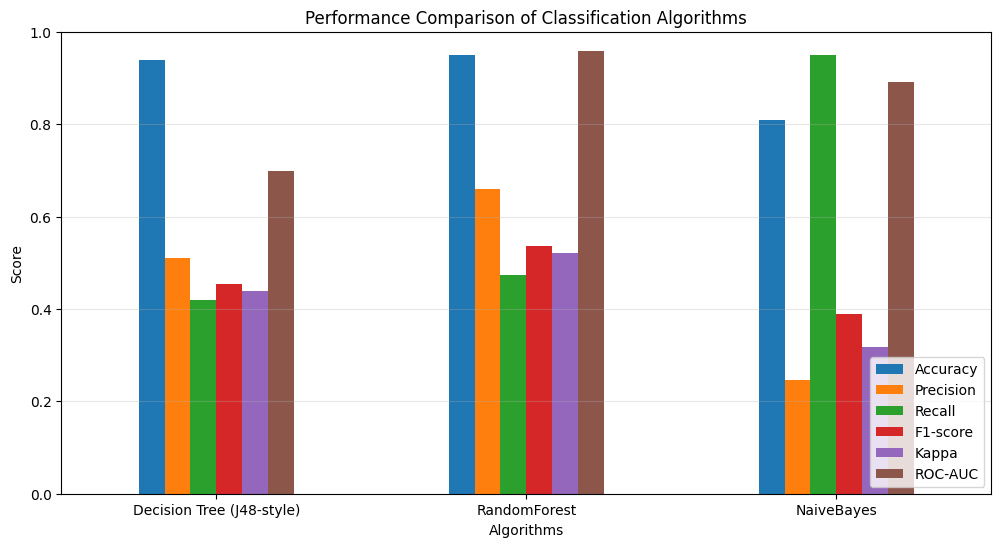

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Kappa",
    "ROC-AUC"
]

results_df[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Classification Algorithms")
plt.ylabel("Score")
plt.xlabel("Algorithms")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

# Identify the best-performing model

In [ ]:
best_model = results_df["F1-score"].idxmax()

print("Best Performing Model:", best_model)

print("\nPerformance:")
print(results_df.loc[best_model].round(4))

Best Performing Model: RandomForest

Performance:
Accuracy     0.9499
Precision    0.6600
Recall       0.4733
F1-score     0.5367
ROC-AUC      0.9581
Kappa        0.5215
Name: RandomForest, dtype: float64


# DELTA MODIFICATIONS – Additional Improvements
**Delta 1 – Feature Selection using Information Gain**
Information Gain identifies features that provide useful information for predicting Biopsy.
# Calculate Information Gain and rank features

Feature Ranking:


,Feature,Information Gain
33,Schiller,0.128789
32,Hinselmann,0.060628
31,Dx,0.023552
34,Citology,0.022113
0,Age,0.018174
25,STDs: Number of diagnosis,0.011983
1,Number of sexual partners,0.008608
10,IUD (years),0.008005
8,Hormonal Contraceptives (years),0.006743
5,Smokes (years),0.006046



Selected Top 10 Features:
['Schiller', 'Hinselmann', 'Dx', 'Citology', 'Age', 'STDs: Number of diagnosis', 'Number of sexual partners', 'IUD (years)', 'Hormonal Contraceptives (years)', 'Smokes (years)']


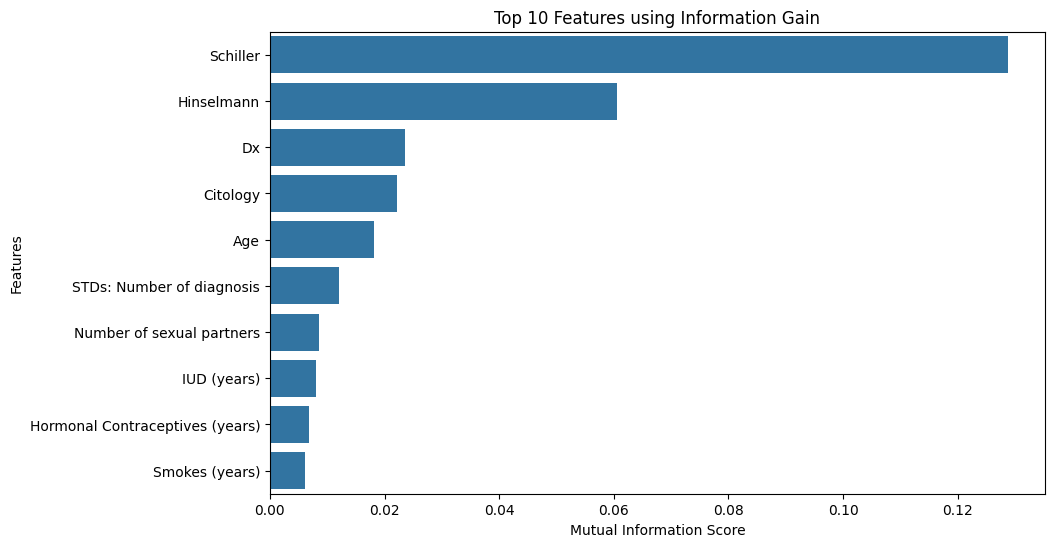

In [ ]:
# Recreate raw features, retaining original missing values
X_model = df.drop(columns=["Biopsy"]).copy()

for col in nominal_columns:
    if col in X_model.columns:
        X_model[col] = X_model[col].apply(
            lambda v: str(int(v)) if pd.notna(v) else np.nan
        )

# Prepare data for feature ranking
X_info = X_model.copy()

info_numeric = X_info.select_dtypes(
    include=["number"]
).columns.tolist()

info_categorical = X_info.select_dtypes(
    include=["object"]
).columns.tolist()

for col in info_numeric:
    X_info[col] = X_info[col].fillna(
        X_info[col].median()
    )

for col in info_categorical:
    X_info[col] = X_info[col].fillna(
        X_info[col].mode()[0]
    )

# Encode categorical values
for col in info_categorical:
    X_info[col] = X_info[col].astype("category").cat.codes

# Identify discrete features
discrete_mask = [
    col in info_categorical for col in X_info.columns
]

# Calculate mutual information
scores = mutual_info_classif(
    X_info,
    y.astype(int),
    discrete_features=discrete_mask,
    random_state=10
)

feature_ranking = pd.DataFrame({
    "Feature": X_info.columns,
    "Information Gain": scores
})

feature_ranking = feature_ranking.sort_values(
    by="Information Gain",
    ascending=False
)

print("Feature Ranking:")
display(feature_ranking)

# Select top 10 features
top_10_features = feature_ranking.head(10)["Feature"].tolist()

print("\nSelected Top 10 Features:")
print(top_10_features)

#visualize top 10 features

top_features = feature_ranking.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Information Gain",
    y="Feature"
)

plt.title("Top 10 Features using Information Gain")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.show()

# Train RandomForest using selected feature

In [ ]:
X_top = X_model[top_10_features].copy()

top_numeric = X_top.select_dtypes(
    include=["number"]
).columns.tolist()

top_categorical = X_top.select_dtypes(
    include=["object"]
).columns.tolist()

top_preprocessor = ColumnTransformer([
    ("numeric",
     Pipeline([
         ("imputer", SimpleImputer(strategy="median")),
         ("scaler", StandardScaler())
     ]),
     top_numeric),

    ("categorical",
     Pipeline([
         ("imputer", SimpleImputer(strategy="most_frequent")),
         ("onehot", OneHotEncoder(handle_unknown="ignore"))
     ]),
     top_categorical)
])

info_rf = ImbPipeline([
    ("preprocessing", top_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=10
    ))
])

info_scores = cross_validate(
    info_rf,
    X_top,
    y.astype(int),
    cv=cv,
    scoring=scoring
)

print("InfoGain + RandomForest Results:")

for metric in scoring:
    print(
        metric,
        round(info_scores["test_" + metric].mean(), 4)
    )

InfoGain + RandomForest Results:
accuracy 0.9511
precision 0.6242
recall 0.6167
f1 0.6132
roc_auc 0.9392


# Delta 2 – Handling Class Imbalance using SMOTE
Your dataset has:
- Negative records = 803
- Positive records = 55
SMOTE generates synthetic minority-class samples to balance the training data.

**Apply SMOTE with RandomForest**
sampling_strategy=1.0 means that SMOTE balances the minority and majority classes in each training fold.

In [ ]:
smote_rf = ImbPipeline([
    ("preprocessing", make_preprocessor()),

    ("smote", SMOTE(
        sampling_strategy=1.0,
        k_neighbors=5,
        random_state=1
    )),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=10
    ))
])

smote_scores = cross_validate(
    smote_rf,
    X_model,
    y.astype(int),
    cv=cv,
    scoring=scoring
)

print("SMOTE + RandomForest Results:")

for metric in scoring:
    print(
        metric,
        round(smote_scores["test_" + metric].mean(), 4)
    )

SMOTE + RandomForest Results:
accuracy 0.9557
precision 0.6364
recall 0.69
f1 0.6563
roc_auc 0.9582


# Verify the SMOTE effect on the training data

In [ ]:
from collections import Counter

# Demonstration on one training fold only
from sklearn.model_selection import StratifiedKFold

train_indices, test_indices = next(
    cv.split(X_model, y.astype(int))
)

X_fold = X_model.iloc[train_indices]
y_fold = y.iloc[train_indices].astype(int)

# Fit preprocessing on training data
preprocessor = make_preprocessor()

X_fold_processed = preprocessor.fit_transform(X_fold)

# Apply SMOTE
smote_demo = SMOTE(
    sampling_strategy=1.0,
    k_neighbors=5,
    random_state=1
)

X_resampled, y_resampled = smote_demo.fit_resample(
    X_fold_processed,
    y_fold
)

print("Before SMOTE:")
print(Counter(y_fold))

print("\nAfter SMOTE:")
print(Counter(y_resampled))

Before SMOTE:
Counter({0: 722, 1: 50})

After SMOTE:
Counter({0: 722, 1: 722})


# Delta 3 – RandomForest Hyperparameter Tuning
**Compare RandomForest with different tree counts**

In [ ]:
tree_values = [100, 200, 300]

tuning_results = {}

for trees in tree_values:

    pipeline = ImbPipeline([
        ("preprocessing", make_preprocessor()),

        ("smote", SMOTE(
            sampling_strategy=1.0,
            k_neighbors=5,
            random_state=1
        )),

        ("classifier", RandomForestClassifier(
            n_estimators=trees,
            random_state=10
        ))
    ])

    scores = cross_validate(
        pipeline,
        X_model,
        y.astype(int),
        cv=cv,
        scoring=scoring
    )

    predictions = cross_val_predict(
        pipeline,
        X_model,
        y.astype(int),
        cv=cv,
        method="predict"
    )

    tuning_results[trees] = {
        "Accuracy": scores["test_accuracy"].mean(),
        "Kappa": cohen_kappa_score(
            y.astype(int), predictions
        ),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "ROC area": scores["test_roc_auc"].mean()
    }

tuning_df = pd.DataFrame(tuning_results).T

tuning_df.index.name = "Number of Trees"

print("RandomForest Hyperparameter Tuning Results:")

display(tuning_df.round(4))

RandomForest Hyperparameter Tuning Results:


,Accuracy,Kappa,Precision,Recall,F1-score,ROC area
Number of Trees,,,,,,
100,0.9557,0.6430,0.6364,0.6900,0.6563,0.9582
200,0.9580,0.6618,0.6554,0.7100,0.6774,0.9587
300,0.9569,0.6552,0.6444,0.7067,0.6661,0.9575


# Generate confusion matrix for the best tree configuration

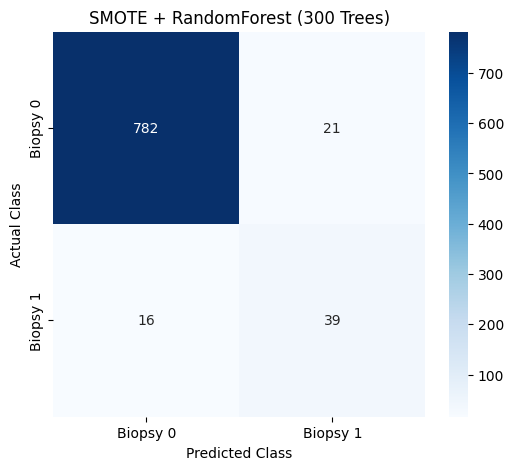


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98       803
           1       0.65      0.71      0.68        55

    accuracy                           0.96       858
   macro avg       0.81      0.84      0.83       858
weighted avg       0.96      0.96      0.96       858

Kappa: 0.6551971326164874


In [ ]:
best_pipeline = ImbPipeline([
    ("preprocessing", make_preprocessor()),

    ("smote", SMOTE(
        sampling_strategy=1.0,
        k_neighbors=5,
        random_state=1
    )),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=10
    ))
])

best_predictions = cross_val_predict(
    best_pipeline,
    X_model,
    y.astype(int),
    cv=cv,
    method="predict"
)

cm = confusion_matrix(
    y.astype(int),
    best_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Biopsy 0", "Biopsy 1"],
    yticklabels=["Biopsy 0", "Biopsy 1"]
)

plt.title("SMOTE + RandomForest (300 Trees)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

print("\nClassification Report:")
print(
    classification_report(
        y.astype(int),
        best_predictions,
        zero_division=0
    )
)

print(
    "Kappa:",
    cohen_kappa_score(y.astype(int), best_predictions)
)

# Compare all modified models

Modified Model Comparison:


,Accuracy,Kappa,Precision,Recall,F1-score,ROC area
Number of Trees,,,,,,
100,0.9557,0.6430,0.6364,0.6900,0.6563,0.9582
200,0.9580,0.6618,0.6554,0.7100,0.6774,0.9587
300,0.9569,0.6552,0.6444,0.7067,0.6661,0.9575


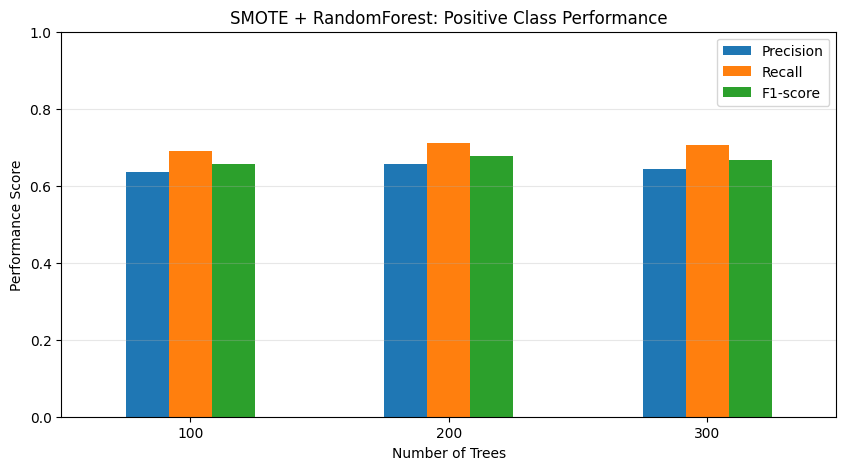

In [ ]:
print("Modified Model Comparison:")

display(tuning_df.round(4))

# Plot comparison
tuning_df[
    ["Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title(
    "SMOTE + RandomForest: Positive Class Performance"
)

plt.xlabel("Number of Trees")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

# Compare baseline and modified accuracy

,Model,Accuracy
0,Baseline RandomForest,0.949891
1,SMOTE + RF (100),0.955718
2,SMOTE + RF (200),0.958044
3,SMOTE + RF (300),0.956895


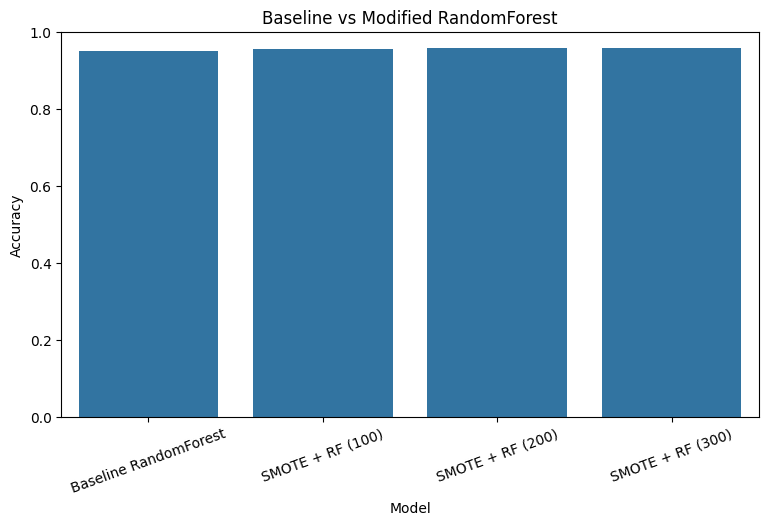

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline RandomForest",
        "SMOTE + RF (100)",
        "SMOTE + RF (200)",
        "SMOTE + RF (300)"
    ],

    "Accuracy": [
        results_df.loc["RandomForest", "Accuracy"],
        tuning_df.loc[100, "Accuracy"],
        tuning_df.loc[200, "Accuracy"],
        tuning_df.loc[300, "Accuracy"]
    ]
})

display(comparison)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Baseline vs Modified RandomForest")
plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.show()

# Save experimental results

In [ ]:
# Save baseline results
results_df.to_csv(
    "Baseline_Classification_Results.csv"
)

# Save RandomForest tuning results
tuning_df.to_csv(
    "RandomForest_Tuning_Results.csv"
)

# Save feature ranking
feature_ranking.to_csv(
    "Information_Gain_Feature_Ranking.csv",
    index=False
)

# Save frequent itemsets
frequent_itemsets.to_csv(
    "Apriori_Frequent_Itemsets.csv",
    index=False
)

# Save association rules
if not rules.empty:
    rules.to_csv(
        "Apriori_Association_Rules.csv",
        index=False
    )

# Save cluster comparison
cluster_comparison.to_csv(
    "KMeans_Cluster_Comparison.csv"
)

print("All result files saved successfully!")

All result files saved successfully!


# Apriori nominal attributes

In [ ]:
# Safely format nominal attributes in apriori_data if they haven't been transformed yet
for col in nominal_columns:
    if col in apriori_data.columns:
        # Only attempt conversion if the values look like numeric floats/ints (not already containing '=')
        sample_val = apriori_data[col].dropna().iloc[0] if not apriori_data[col].dropna().empty else ""
        if "=" not in str(sample_val):
            apriori_data[col] = apriori_data[col].apply(
                lambda v: str(int(float(v))) if pd.notna(v) and str(v).replace('.', '', 1).isdigit() else str(v)
            )